# Machine Learning - Practical 3 - Multiclass Logistic Regression, MLP and CNNs

**Authors:** Muhammed Nagaş, Felix Fischer, Niclas Langer  
Summer term 2026

*Machine Learning course, University of Göttingen, summer term 2026. The exercise template (task text, helper code) was provided by the course; the solutions and answers are ours.*

**Note:** this notebook trains several models on CIFAR-10. It was run on a Kaggle GPU; on a CPU it takes considerably longer. The CIFAR-10 data set is downloaded automatically by `torchvision` into `./data`.

In this practical we will implement multiclass classification with classic Logistic Regression, Multilayer Perceptron, and the convolutional neural network LeNet5 on image data. We will compare the performance of these models. You will work on the following:

 1. Imports and Hardware check
 2. Loading data and related transformations 
 3. Defining training helper functions and metrics 
 4. Logistic Regression 
 5. MLP
 6. CNN
 7. Comparison of results across models

We'll be storing all the losses and accuracies while training, and plotting everything in the end. Use `tqdm` to keep track of your training and validation losses and accuracies since we're only plotting them in the end.

In [2]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import torchsummary


torch.manual_seed(42) # Set manual seed

In [3]:
# DO NOT CHANGE
use_cuda = True
use_cuda = False if not use_cuda else torch.cuda.is_available()
device = torch.device('cuda:0' if use_cuda else 'cpu')
torch.cuda.get_device_name(device) if use_cuda else 'cpu'
print('Using device', device)

Using device cpu


## Define data transformations

We will work with the CIFAR-10 dataset, an established computer vision dataset used for object recognition. It is a subset of the 80 million tiny images dataset and consists of 60,000 32x32 color images containing one of 10 object classes, with 6000 images per class. It was collected by Alex Krizhevsky, Vinod Nair, and Geoffrey Hinton. The goal of this dataset is to predict the image class.

Note: The constants in `transforms.Normalize()` are the means and standard deviations of the three color channels of the images in the CIFAR-10 training set. You can verify these numbers yourself by re-computing them.

In [4]:
batch_size = 256

train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

test_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

In [5]:
# Load the data and transform the dataset
train_dataset = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transforms)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transforms)

# You can verify the mean and standard deviation used in the normalization above by calculating the mean and std of the training dataset above.  

100%|██████████| 170M/170M [00:05<00:00, 30.7MB/s] 


In [6]:
# TODO: make dataloaders (from torch.utils) from datasets, define batch size and do not forget shuffling 

from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

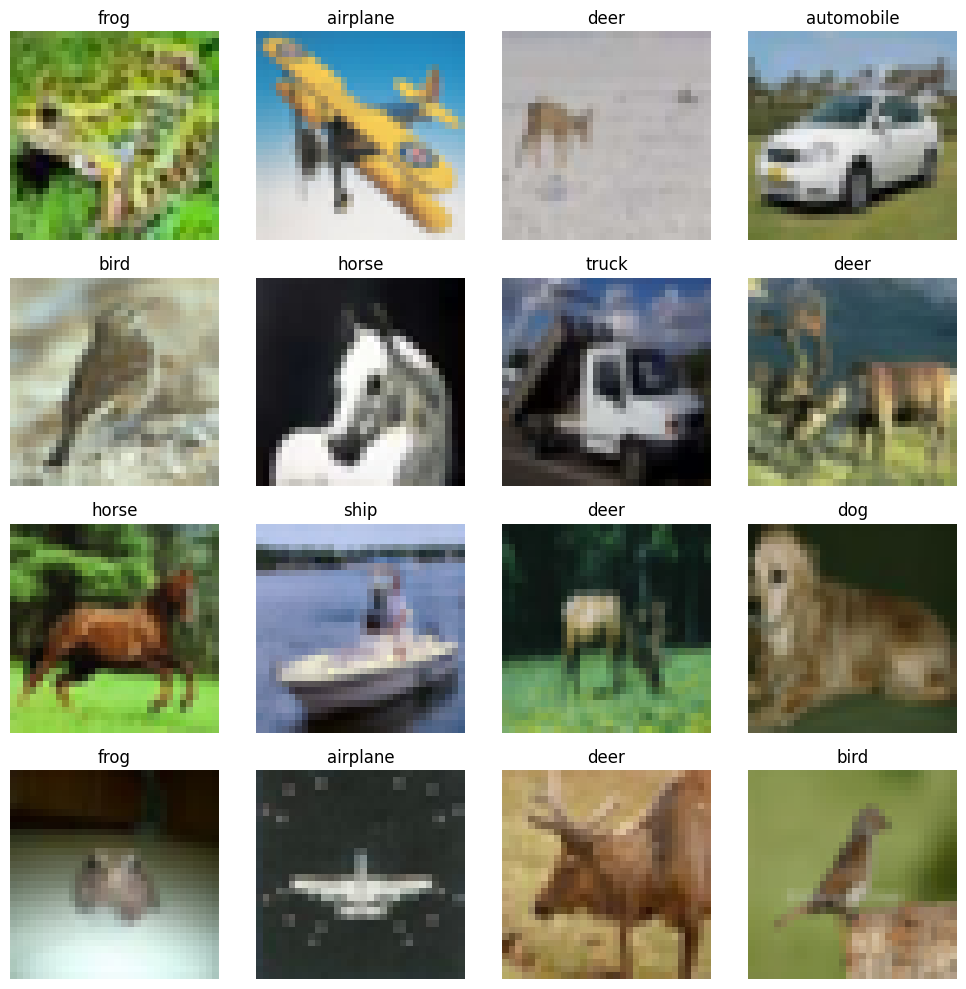

In [7]:
## TODO: plot images with their labels after augmentations
def show_batch(dl):
    # Fetch a single batch of images and labels
    images, labels = next(iter(dl))
    
    # Define the text labels for CIFAR-10
    classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 
               'dog', 'frog', 'horse', 'ship', 'truck']
    
    # Plot the first 16 images in a 4x4 grid
    fig, axes = plt.subplots(4, 4, figsize=(10, 10))
    for i, ax in enumerate(axes.flatten()):
        # Retrieve the image and transpose it for matplotlib
        img = images[i].numpy().transpose((1, 2, 0))
        
        # Un-normalize the image: img = img * std + mean
        mean = np.array([0.4914, 0.4822, 0.4465])
        std = np.array([0.2470, 0.2435, 0.2616])
        img = std * img + mean
        img = np.clip(img, 0, 1) # Ensure values are strictly bounded between 0 and 1
        
        ax.imshow(img)
        ax.set_title(f"{classes[labels[i]]}")
        ax.axis("off")
        
    plt.tight_layout()
    plt.show()

# Call the function to display the batch
show_batch(train_loader)

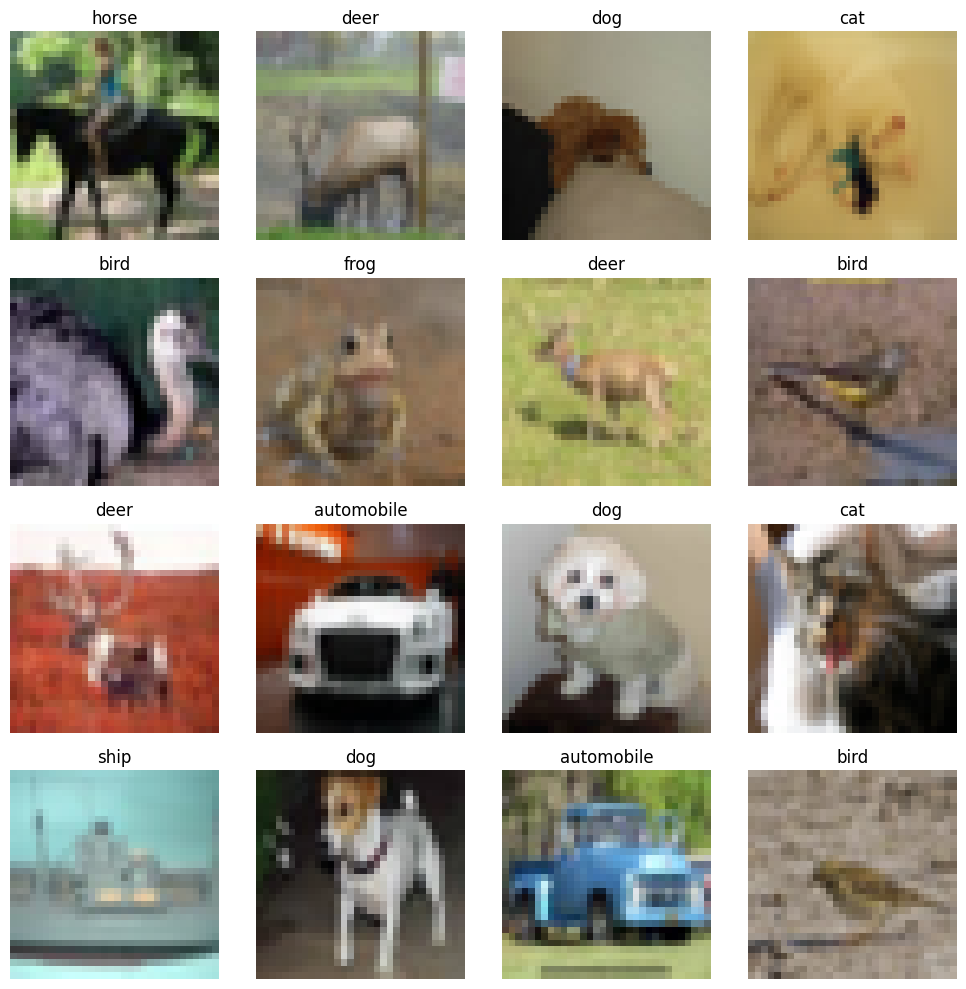

In [8]:
show_batch(train_loader)

In [9]:
num_classes = 10

## Define helper functions for training and metrics

You will need these again and again. 

In [10]:
## TODO: write a function that calculates the accuracy

def accuracy(correct, total): 
    """
    function to calculate the accuracy given the
        correct: number of correctly classified samples
        total: total number of samples
    returns the ratio
    """
    return correct / total if total > 0 else 0.0

In [11]:
## TODO: Define a train and validation functions here
## Hint - you can use yours from Practical 2 


def train(dataloader, optimizer, model, loss_fn, device, master_bar):
    """ method to train the model """
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0
    
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * x.size(0)
        _, preds = torch.max(out, 1)
        correct += (preds == y).sum().item()
        total += y.size(0)
        
    return total_loss / total, accuracy(correct, total)


def validate(dataloader, model, loss_fn, device, master_bar):
    """ method to compute the metrics on the validation set """
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            
            total_loss += loss.item() * x.size(0)
            _, preds = torch.max(out, 1)
            correct += (preds == y).sum().item()
            total += y.size(0)
            
    return total_loss / total, accuracy(correct, total)
    

In [12]:
#TODO: write a run_training function that 
# - calls the train and validate functions for each epoch
# - saves the train_losses, val_losses, train_accs, val_accs as arrays for each epoch
## Hint - you can use yours from Practical 2 
from tqdm.notebook import trange

def run_training(model, optimizer, loss_function, device, num_epochs, train_dataloader, val_dataloader):
    """ method to run the training procedure """
    train_losses, val_losses = [], []
    train_accs, val_accs = [], []
    
    master_bar = trange(num_epochs, desc="Epochs")
    for epoch in master_bar:
        train_loss, train_acc = train(train_dataloader, optimizer, model, loss_function, device, master_bar)
        val_loss, val_acc = validate(val_dataloader, model, loss_function, device, master_bar)
        
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        
        # Update progress bar metrics
        master_bar.set_postfix(
            train_loss=f"{train_loss:.4f}", 
            val_loss=f"{val_loss:.4f}", 
            train_acc=f"{train_acc:.4f}", 
            val_acc=f"{val_acc:.4f}"
        )
        
    return train_losses, val_losses, train_accs, val_accs

In [13]:
# TODO: write a function to calculate and return the confusion values
from sklearn.metrics import confusion_matrix

def calc_confusion_values(dataloader, model, device):
    """ method to compute the confusion values on the validation set """
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)
            out = model(x)
            _, preds = torch.max(out, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y.numpy())
            
    return confusion_matrix(all_targets, all_preds)

## Logistic Regression   

In [14]:
# TODO: define logistic regression model class and its necessary functions
# What are the dimensions of your input layer?
# TODO: flatten the input to a suitable size for the initial layer

# CIFAR-10 images are 3 channels of 32x32 pixels, so input features = 3 * 32 * 32 = 3072
input_dim = 3 * 32 * 32
output_dim = 10

class LogisticRegressionModel(nn.Module):
    def __init__(self, input_size, num_classes):
        super(LogisticRegressionModel, self).__init__()
        self.linear = nn.Linear(input_size, num_classes)
        
    def forward(self, x):
        x = x.view(x.size(0), -1) # Flatten the input
        return self.linear(x)



In [15]:
logistic_regression = LogisticRegressionModel(input_dim, output_dim).to(device)

In [16]:
## Optimizer defined. We're going to use Adam since it's always the safe bet, and also for faster convergence. 
optimizer = torch.optim.Adam(logistic_regression.parameters(), lr=0.001)


### Define loss 

Since we're dealing with multi-class classification (i.e. multiple categories), softmax is the canonical choice for the final layer activation. Softmax provides us with a distribution of values in \[0, 1\] that sum up to 1 over all categories.

We then use the cross entropy to compute the loss.

Hint: Due to numerical reasons, softmax and cross entropy are combined into one operation. Read more about it in https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html.

In [17]:
# TODO: define the loss function
loss_fn = nn.CrossEntropyLoss()

In [18]:

## TODO: run training over 20 epochs
num_epochs = 20

lr_train_losses, lr_val_losses, lr_train_accs, lr_val_accs = run_training(
    model=logistic_regression, 
    optimizer=optimizer, 
    loss_function=loss_fn, 
    device=device, 
    num_epochs=num_epochs, 
    train_dataloader=train_loader, 
    val_dataloader=test_loader
)

## Multilayer Perceptron

MLP is a network which consists of several linear fully-connected layers with non-linearities between them.

### Question:
Why are non-linearities between linear layers important?

If we only stack linear layers without non-linear activations in between, the entire sequence mathematically collapses into a single linear transformation (because the product of matrices is just another matrix). Adding non-linearities (like ReLU) breaks this linearity, allowing the network to model complex, highly non-linear relationships and act as a universal function approximator.

In [19]:
## TODO: Make the 4 layer MLP  with the following shapes :
## input_dim -> 2048 -> 512 -> 128 -> output_dim
## Use RELu as nonlinearity
## In the forward pass do not forget to flatten the input
class MLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super(MLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 2048),
            nn.ReLU(),
            nn.Linear(2048, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )
        
    def forward(self, x):
        x = x.view(x.size(0), -1) # Flatten
        return self.network(x)

mlp_model = MLP(input_dim, output_dim).to(device)

In [20]:
## TODO: Define network, put it to device and train mode
mlp_model = MLP(input_dim, output_dim).to(device)

In [21]:
## TODO: Define optimizer and loss functions
mlp_optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.001)
mlp_loss_fn = nn.CrossEntropyLoss()

In [22]:
## TODO: Train the MLP over 20 epochs
mlp_train_losses, mlp_val_losses, mlp_train_accs, mlp_val_accs = run_training(
    model=mlp_model, 
    optimizer=mlp_optimizer, 
    loss_function=mlp_loss_fn, 
    device=device, 
    num_epochs=num_epochs, 
    train_dataloader=train_loader, 
    val_dataloader=test_loader
)

## Add L2 regularisation

In [23]:
# TODO: Define new model, optimizer, put model to device, etc.
## 0.00005 is a good starting point for the regularization strength

mlp_reg_model = MLP(input_dim, output_dim).to(device)

# Weight decay inherently applies L2 regularization in PyTorch's Adam/SGD
mlp_reg_optimizer = torch.optim.Adam(mlp_reg_model.parameters(), lr=0.001, weight_decay=0.00005)

mlp_reg_train_losses, mlp_reg_val_losses, mlp_reg_train_accs, mlp_reg_val_accs = run_training(
    model=mlp_reg_model, 
    optimizer=mlp_reg_optimizer, 
    loss_function=mlp_loss_fn, 
    device=device, 
    num_epochs=num_epochs, 
    train_dataloader=train_loader, 
    val_dataloader=test_loader
)

In [24]:
## TODO: Retrain new model with regularization over 20 epochs
# NOTE: this continues training the model from the cell above, so the regularised
# MLP is trained for 40 epochs in total and the curves below show epochs 21-40.
mlp_reg_train_losses, mlp_reg_val_losses, mlp_reg_train_accs, mlp_reg_val_accs = run_training(
    model=mlp_reg_model, 
    optimizer=mlp_reg_optimizer, 
    loss_function=mlp_loss_fn, 
    device=device, 
    num_epochs=num_epochs, 
    train_dataloader=train_loader, 
    val_dataloader=test_loader
)

## LeNet5

*LeNet-5 architecture: two convolution + pooling stages followed by three fully-connected layers (see the original paper linked below).*

Let's implememt one of the classical convolutional network and apply it for CIFAR-10. Here is the link for the [original paper](http://vision.stanford.edu/cs598_spring07/papers/Lecun98.pdf) of LeNet5 introduced by Yann LeCun and colleagues in 1998. The original implementation of LeNet5 has Tanh as nonlinearities. In 2012, AlexNet famously set off the deep learning revolution. AlexNet is based on LeNet, with two main innovations: (1) making it deeper by adding a few extra layers and (2) replacing the tanh activation functions by ReLU to improve training. Here we'll the original LeNet5 architecture to keep the compute requirements small, but work with the more modern ReLU activation functions.

One more thing we change in the original network is the number of input channels as LeNet5 was designed for grayscale MNIST dataset, where each picture has 1 channel, while for RGB pictures we have 3 channels in the input data.


In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class LeNet5(nn.Module):
    def __init__(self, num_classes=10):
        super(LeNet5, self).__init__()
        
        # 1st Convolutional Layer: Since CIFAR-10 images are colored (RGB),
        # there are 3 input channels.
        # This layer uses 6 different filters (output channels)
        # to capture basic edges and pixel patterns in the image.
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5)
        
        # Pooling Layer: Reduces the image size by half
        # to summarize the most important features.
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        
        # 2nd Convolutional Layer:
        # Takes the 6 channels from the previous layer
        # and increases them to 16 channels to detect more complex patterns.
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        
        # Fully Connected (Classic Neural Network) Layers:
        # After convolution and pooling operations,
        # the feature maps become 16 channels with size 5x5.
        # Therefore, the input size becomes 16 * 5 * 5 = 400.
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)  # Final layer: produces predictions for 10 different classes.

    def forward(self, x):
        # Define the flow of data through the network:
        
        # 1st Convolution -> Activation (ReLU) -> Pooling
        x = self.pool(F.relu(self.conv1(x)))
        
        # 2nd Convolution -> Activation (ReLU) -> Pooling
        x = self.pool(F.relu(self.conv2(x)))
        
        # Flatten the 2D feature maps into a vector
        # so they can be passed into the fully connected layers.
        x = x.view(-1, 16 * 5 * 5)
        
        # Pass through the fully connected layers with activations:
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        
        # Final output layer (prediction scores)
        x = self.fc3(x) 
        return x

In [26]:
## TODO: define network, put it to the device and train mode
lenet_model = LeNet5(num_classes=num_classes).to(device)

For a quick overview of models, torchsummary.summary is quite helpful  
comment: You can also import predefined architectures from `torchvision` and run `torchsummary.summary` on them to get a quick overview

In [ ]:
## TODO: run torchsummary.summary on the LeNet5 and your MLP model. What do you see?
print("MLP:")
torchsummary.summary(mlp_model, (3, 32, 32), device=device.type)
print("\nLeNet5:")
torchsummary.summary(lenet_model, (3, 32, 32), device=device.type)

MLP:
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                 [-1, 2048]       6,293,504
              ReLU-2                 [-1, 2048]               0
            Linear-3                  [-1, 512]       1,049,088
              ReLU-4                  [-1, 512]               0
            Linear-5                  [-1, 128]          65,664
              ReLU-6                  [-1, 128]               0
            Linear-7                   [-1, 10]           1,290
Total params: 7,409,546
Trainable params: 7,409,546
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 0.04
Params size (MB): 28.27
Estimated Total Size (MB): 28.32
----------------------------------------------------------------

LeNet5:
----------------------------------------------------------------
        Layer (type) 

In [28]:
## TODO: define loss function and optimizer
lenet_optimizer = torch.optim.Adam(lenet_model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

In [29]:
EPOCHS = 20

print("LeNet-5 is starting, it can take a long time..")

# We start the training process by calling the previously defined run_training function.
# As output, we obtain the loss and accuracy histories so that we can plot graphs later.

lenet_train_loss, lenet_val_loss, lenet_train_acc, lenet_val_acc = run_training(
    model=lenet_model,
    optimizer=lenet_optimizer,
    loss_function=loss_fn,
    device=device,
    num_epochs=EPOCHS,
    train_dataloader=train_loader,  # Updated to match defined variable
    val_dataloader=test_loader      # Updated from val_loader to test_loader
)

print("Completed!")

LeNet-5 is starting, it can take a long time..


Completed!


## Analysis 

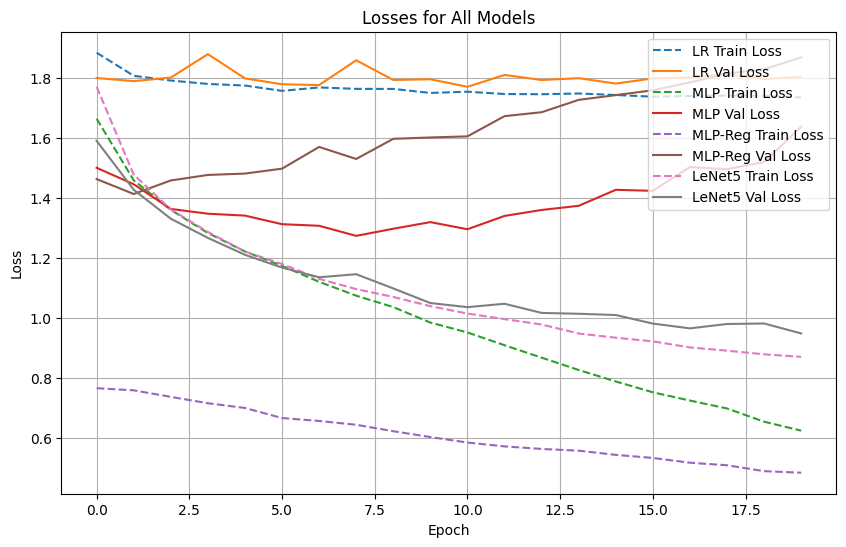

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# --- Plot: Loss Values for All Models ---
plt.plot(lr_train_losses, label='LR Train Loss', linestyle='--')
plt.plot(lr_val_losses, label='LR Val Loss', linestyle='-')
plt.plot(mlp_train_losses, label='MLP Train Loss', linestyle='--')
plt.plot(mlp_val_losses, label='MLP Val Loss', linestyle='-')
plt.plot(mlp_reg_train_losses, label='MLP-Reg Train Loss', linestyle='--')
plt.plot(mlp_reg_val_losses, label='MLP-Reg Val Loss', linestyle='-')
plt.plot(lenet_train_loss, label='LeNet5 Train Loss', linestyle='--')
plt.plot(lenet_val_loss, label='LeNet5 Val Loss', linestyle='-')

plt.title('Losses for All Models')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

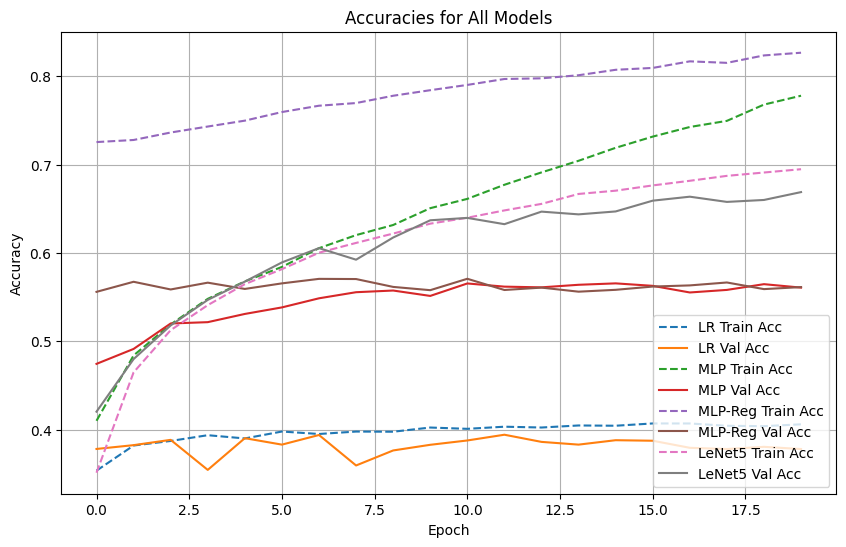

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# --- Plot: Accuracy Values for All Models ---
plt.plot(lr_train_accs, label='LR Train Acc', linestyle='--')
plt.plot(lr_val_accs, label='LR Val Acc', linestyle='-')
plt.plot(mlp_train_accs, label='MLP Train Acc', linestyle='--')
plt.plot(mlp_val_accs, label='MLP Val Acc', linestyle='-')
plt.plot(mlp_reg_train_accs, label='MLP-Reg Train Acc', linestyle='--')
plt.plot(mlp_reg_val_accs, label='MLP-Reg Val Acc', linestyle='-')
plt.plot(lenet_train_acc, label='LeNet5 Train Acc', linestyle='--')
plt.plot(lenet_val_acc, label='LeNet5 Val Acc', linestyle='-')

plt.title('Accuracies for All Models')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

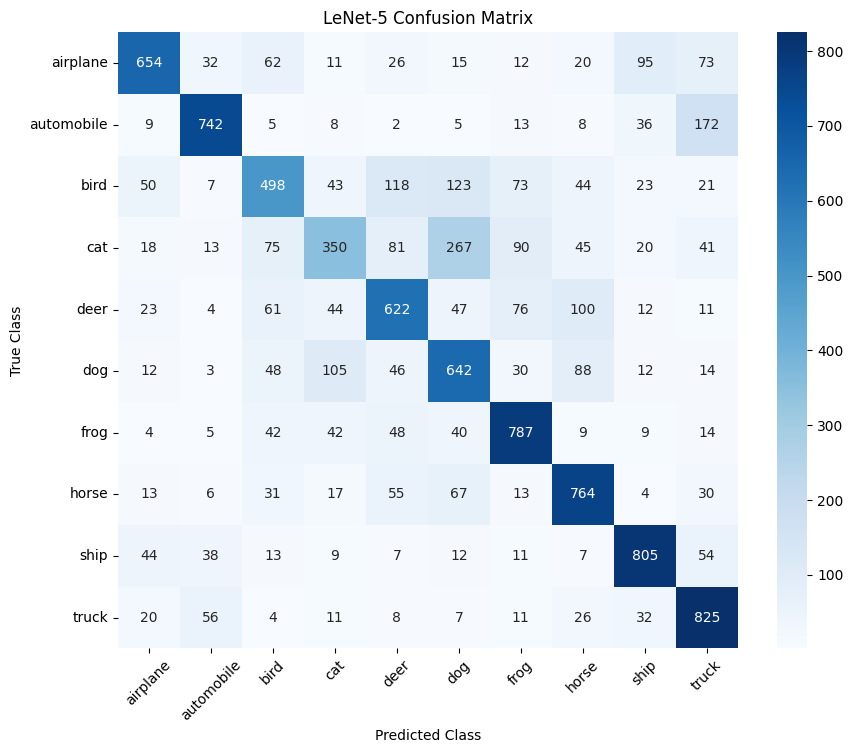

In [32]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np
import torch

# Names of the 10 classes in the CIFAR-10 dataset
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 
           'dog', 'frog', 'horse', 'ship', 'truck']

# Set the model to evaluation mode
lenet_model.eval()

all_preds = []
all_labels = []

# Turn off gradient calculations inside the model to speed it up
with torch.no_grad():
    for images, labels in test_loader:  # Updated from val_loader to test_loader
        images, labels = images.to(device), labels.to(device)
        outputs = lenet_model(images)
        
        # Find the predicted class with the highest probability
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

# Visualize as a Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=classes, yticklabels=classes)
plt.title('LeNet-5 Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.xticks(rotation=45)
plt.show()

### Results at a glance (test set, after training)

| Model | Test accuracy |
|---|---|
| Logistic regression | ≈ 39 % |
| MLP (4 layers) | ≈ 56 % |
| MLP + L2 (weight decay) | ≈ 56 % |
| LeNet-5 (CNN) | ≈ 67 % |

Note that the regularised MLP was trained for 40 epochs (two consecutive training calls), so its curves are not directly comparable to the plain MLP: its training accuracy keeps rising while the test accuracy stays at ~56 %.

## Questions
* How did regularization change the performance of the MLP? Why?
* Explain the confusion matrix for LeNet5. What do you see there?
* Explain the difference in performance between linear regression, MLP, and LeNet5.
* Why are convolutions better suited for pictures? Which properties of images do they exploit?
* Is it important to redefine an optimizer for each different model, training? What about loss functions?

### Answers to the Questions

**1. How did regularization change the performance of the MLP? Why?**
Regularization (like L2/weight decay) penalizes large weights, preventing the model from overfitting to the training data. You should notice that the gap between training accuracy and validation accuracy becomes smaller. While the training accuracy might be slightly reduced compared to the unregularized MLP, the validation accuracy often stabilizes or improves because the model generalizes better to unseen data.

**2. Explain the confusion matrix for LeNet5. What do you see there?**
The confusion matrix displays the true classes on the y-axis and the predicted classes on the x-axis. A perfect model would only have values on the main diagonal. In the heatmap, we can identify which classes the model frequently confuses. For example, vehicles like "automobile" and "truck" or animals like "cat" and "dog" often have higher misclassification rates (off-diagonal numbers) because they share visually similar features.

**3. Explain the difference in performance between linear regression, MLP, and LeNet5.**
- **Logistic Regression** is a linear model and generally performs the worst on complex image data like CIFAR-10 because it cannot capture non-linear relationships and treats all pixels independently.
- **MLP (Multilayer Perceptron)** performs better because its hidden layers and non-linear activations (ReLU) allow it to learn complex patterns. However, since it flattens the 2D image into a 1D vector, it loses spatial structure and positional information.
- **LeNet5 (CNN)** performs the best. Its convolutional layers preserve the spatial grid of the image, allowing it to efficiently learn local patterns (like edges, textures, and shapes) and build robust hierarchical features.

**4. Why are convolutions better suited for pictures? Which properties of images do they exploit?**
Convolutions exploit two main properties of images:
1. **Spatial Locality:** Pixels close to each other are strongly related and form local features (e.g., edges or corners).
2. **Translation Invariance:** A feature (like an eye or a wheel) is the same regardless of where it appears in the image. 
Additionally, through parameter sharing (using the same filter across the entire image), CNNs have far fewer parameters than MLPs, which makes them easier to train and less prone to overfitting.

**5. Is it important to redefine an optimizer for each different model, training? What about loss functions?**
- **Optimizer:** Yes, it is crucial to define a new optimizer for each model. The optimizer maintains a state specific to the parameters of the model it was initialized with (`model.parameters()`). If you reuse an optimizer for a new model, it will attempt to update the weights of the old model.
- **Loss Function:** No, it is not strictly necessary. A loss function object (like `nn.CrossEntropyLoss()`) generally does not hold any model-specific internal state or parameters, so the same instance can be reused across different models.

## Additional experiments (Optional)
* Try to replace CIFAR10 dataset with MNIST. What do you notice? Why? Try to explain the differences in terms of variance or dataset complexity
